# MobileNetV2 on Imagenette: FP32 vs FP16 vs INT8 (PTQ & QAT) with TensorRT

**Archived run** executed on Kaggle (Tesla T4, TensorRT 8.4.3, pytorch-quantization), September 2024.
Outputs below are the recorded results of that run and are the source of the numbers in the README.

Pipeline:
1. Fine-tune a MobileNetV2 classifier on Imagenette (10 ImageNet classes).
2. Export to ONNX and build TensorRT engines in **FP32** and **FP16**.
3. **Post-training quantization (PTQ):** insert fake-quant nodes, calibrate (max for weights,
   histogram for activations), build an INT8 engine.
4. **Layer sensitivity analysis:** gradient-based sensitivity and saliency per layer, to see which
   layers are most fragile under quantization.
5. **Quantization-aware training (QAT):** fine-tune with fake-quant, build an INT8 engine.
6. Benchmark every engine with `trtexec` and evaluate accuracy with the TensorRT runtime.

> Adapted from the torch-tensorrt example notebooks.

## 1. Setup

In [ ]:
# Environment setup (Kaggle GPU image, Tesla T4). Install output omitted.
!pip install --upgrade --index-url https://pypi.ngc.nvidia.com nvidia-tensorrt
!sudo apt-get install -y tensorrt python3-libnvinfer-dev onnx-graphsurgeon
!pip install --no-cache-dir --index-url https://pypi.nvidia.com pytorch-quantization
!pip install numpy onnx onnxruntime onnxsim wget

In [1]:
import tensorrt
print(tensorrt.__version__)
assert tensorrt.Builder(tensorrt.Logger())

8.4.3.1


In [2]:
import torch
import torch.nn as nn
import torch.backends.cudnn as cudnn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.transforms as transforms
from torchvision import models, datasets
from torch.utils.tensorboard import SummaryWriter
import onnxruntime
import onnxsim
# import torch_tensorrt

import pytorch_quantization
from pytorch_quantization import nn as quant_nn
from pytorch_quantization import quant_modules
from pytorch_quantization import calib
from pytorch_quantization.tensor_quant import QuantDescriptor
from pytorch_quantization.nn.modules.tensor_quantizer import TensorQuantizer
from pytorch_quantization.nn.modules import quant_pooling
from tqdm import tqdm

print(pytorch_quantization.__version__)
# print(torch_tensorrt.__version__)
print(torch.__version__)
print(torchvision.__version__)
#print(torchaudio.__version__)

import os
import sys
import warnings
import time
import numpy as np
import wget
import tarfile
import shutil
warnings.simplefilter('ignore')
import collections

from absl import logging
logging.set_verbosity(logging.FATAL)  # Disable logging as they are too noisy in notebook

import json


!mkdir -p /root/.cache/torch/hub/checkpoints/
!cp /kaggle/input/few-imagenet-examples/efficientnet_b0_ra-3dd342df.pth /root/.cache/torch/hub/checkpoints/
!cp /kaggle/input/few-imagenet-examples/efficientnet_b2_ra-bcdf34b7.pth /root/.cache/torch/hub/checkpoints/

# loading labels
with open("/kaggle/input/few-imagenet-examples/data/imagenet_class_index.json") as json_file: 
    d = json.load(json_file)

2.1.3
1.11.0
0.12.0


## 2. Data: Imagenette

In [ ]:
!tar xzvf /kaggle/input/imagenette/imagenette2-320.tgz

In [ ]:
# Define main data directory
DATA_DIR = '/kaggle/working/imagenette2-320' 
# Define training and validation data paths
TRAIN_DIR = os.path.join(DATA_DIR, 'train') 
VAL_DIR = os.path.join(DATA_DIR, 'val')

In [ ]:
#Performing Transformations on the dataset and defining training and validation dataloaders
transform = transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            ])
train_dataset = datasets.ImageFolder(TRAIN_DIR, transform=transform)
val_dataset = datasets.ImageFolder(VAL_DIR, transform=transform)
calib_dataset = torch.utils.data.random_split(val_dataset, [2901, 1024])[1]

train_dataloader = data.DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True,pin_memory=True,num_workers=4)
val_dataloader = data.DataLoader(val_dataset, batch_size=32, shuffle=False, drop_last=True,pin_memory=True,num_workers=4)
calib_dataloader = data.DataLoader(calib_dataset, batch_size=32, shuffle=False, drop_last=True,pin_memory=True,num_workers=4)


#Data Augmentation can be done

tensor(0)


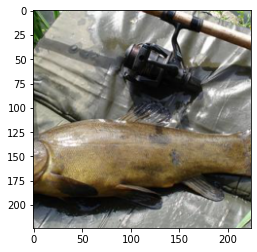

In [3]:
# Visualising an image from the validation set
import matplotlib.pyplot as plt
for images, labels in val_dataloader:
    print(labels[0])
    image = images[0]
    img = image.swapaxes(0, 1)
    img = img.swapaxes(1, 2)
    plt.imshow(img)
    break

## 3. FP32 baseline
MobileNetV2 with a 10-class head, fine-tuned for 10 epochs.

In [ ]:
#This function allows you to set the all the parameters to not have gradients, 
#allowing you to freeze the model and not undergo training during the train step. 
def set_parameter_requires_grad(model, feature_extracting):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False

feature_extract = True #This varaible can be set False if you want to finetune the model by updating all the parameters. 
#--------Load Torchvision Model------------------
model = models.mobilenet_v2(pretrained=True)
set_parameter_requires_grad(model, feature_extract)
#Define a classification head for 10 classes.
#-----Mobilenetv2---------------------------
model.classifier[1] = nn.Linear(1280, 10)
# num_ftrs = model.fc.in_features
# model.fc = nn.Linear(num_ftrs, 10)
#-------------------------------------------
model = model.cuda()

In [ ]:
# Declare Learning rate
lr = 0.001

# Use cross entropy loss for classification and SGD optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

In [ ]:
# Define functions for training, evalution, saving checkpoint and train parameter setting function
def train(model, dataloader, crit, opt, epoch):
    model.train()
    running_loss = 0.0
    running_corrects = 0  # Initialize correct predictions count

    for batch, (data, labels) in enumerate(dataloader):
        data, labels = data.cuda(), labels.cuda(non_blocking=True)

        # Zero the parameter gradients
        opt.zero_grad()

        # Forward pass
        out = model(data)
        loss = crit(out, labels)

        # Backward pass and optimize
        loss.backward()
        opt.step()

        # Accumulate loss
        running_loss += loss.item()

        # Calculate number of correct predictions in this batch
        _, preds = torch.max(out, 1)  # Get the index of the max log-probability
        running_corrects += torch.sum(preds == labels.data)

        # Print statistics every 100 batches
        if batch % 100 == 99:
            print("Batch: [%5d | %5d] loss: %.3f" % (batch + 1, len(dataloader), running_loss / 100))
            running_loss = 0.0  # Reset running loss

    # Calculate final loss and accuracy for the entire epoch
    train_loss = running_loss / len(dataloader)  # Average loss
    train_acc = running_corrects.double() / len(dataloader.dataset)  # Accuracy as a percentage
    return train_loss, train_acc 
    

def evaluate(model, dataloader, crit, epoch, dtype='fp32'):
    total = 0
    correct = 0
    loss = 0.0
    class_probs = []
    class_preds = []

    model.eval()
    with torch.no_grad():
        for data, labels in dataloader:
            if dtype=='fp16':
                data, labels = data.cuda().half(), labels.cuda(non_blocking=True)
            else:
                data, labels = data.cuda(), labels.cuda(non_blocking=True)
            out = model(data)
            loss += crit(out, labels)
            preds = torch.max(out, 1)[1]
            class_probs.append([F.softmax(i, dim=0) for i in out])
            class_preds.append(preds)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    evaluate_probs = torch.cat([torch.stack(batch) for batch in class_probs])
    evaluate_preds = torch.cat(class_preds)

    return loss / total, correct / total

def save_checkpoint(state, ckpt_path="checkpoint.pth"):
    torch.save(state, ckpt_path)
    print("Checkpoint saved")
    
# Helper function to benchmark the model
cudnn.benchmark = True
def benchmark(model, input_shape=(1024, 1, 32, 32), dtype='fp32', nwarmup=50, nruns=1000):
    input_data = torch.randn(input_shape)
    input_data = input_data.to("cuda")
    if dtype=='fp16':
        input_data = input_data.half()
        
    print("Warm up ...")
    with torch.no_grad():
        for _ in range(nwarmup):
            features = model(input_data)
    torch.cuda.synchronize()
    
    print("Start timing ...")
    timings = []
    with torch.no_grad():
        for i in range(1, nruns+1):
            start_time = time.time()
            output = model(input_data)
            torch.cuda.synchronize()
            end_time = time.time()
            timings.append(end_time - start_time)
#             if i%10==0:
#                 print('Iteration %d/%d, avg batch time %.2f ms'%(i, nruns, np.mean(timings)*1000))

    print("Input shape:", input_data.size())
    print("Output features size:", features.size())
    print('Average batch time: %.2f ms'%(np.mean(timings)*1000))
    print('Average throughput: %.2f images/second'%(input_shape[0]/np.mean(timings)))

In [4]:
# Train the model for 5 epochs to attain an acceptable accuracy.
num_epochs=10
for epoch in range(num_epochs):
    print('Epoch: [%5d / %5d] LR: %f' % (epoch + 1, num_epochs, lr))

    train_loss, train_acc = train(model, train_dataloader, criterion, optimizer, epoch)
    test_loss, test_acc = evaluate(model, val_dataloader, criterion, epoch)
    print(f"Epoch {epoch} - Training Loss: {train_loss:.2f}, Training Accuracy: {100*train_acc:.2f}")
    print(f"Epoch {epoch} - Test Loss: {test_loss:.2f}, Test Accuracy: {100*test_acc:.2f}")
    #print("Test Acc: {:.2f}%".format(100 * test_acc))
    
    
save_checkpoint({'epoch': epoch + 1,
                 'model_state_dict': model.state_dict(),
                 'acc': test_acc,
                 'opt_state_dict': optimizer.state_dict()
                 },
                ckpt_path="/kaggle/working/mobilenetv2_base_ckpt")

Epoch: [    1 /    10] LR: 0.001000
Batch: [  100 |   295] loss: 2.028
Batch: [  200 |   295] loss: 1.435
Epoch 0 - Training Loss: 0.34, Training Accuracy: 69.78
Epoch 0 - Test Loss: 0.03, Test Accuracy: 94.85
Epoch: [    2 /    10] LR: 0.001000
Batch: [  100 |   295] loss: 0.836
Batch: [  200 |   295] loss: 0.670
Epoch 1 - Training Loss: 0.19, Training Accuracy: 94.59
Epoch 1 - Test Loss: 0.01, Test Accuracy: 97.18
Epoch: [    3 /    10] LR: 0.001000
Batch: [  100 |   295] loss: 0.522
Batch: [  200 |   295] loss: 0.457
Epoch 2 - Training Loss: 0.13, Training Accuracy: 95.83
Epoch 2 - Test Loss: 0.01, Test Accuracy: 97.54
Epoch: [    4 /    10] LR: 0.001000
Batch: [  100 |   295] loss: 0.378
Batch: [  200 |   295] loss: 0.350
Epoch 3 - Training Loss: 0.11, Training Accuracy: 96.56
Epoch 3 - Test Loss: 0.01, Test Accuracy: 97.64
Epoch: [    5 /    10] LR: 0.001000
Batch: [  100 |   295] loss: 0.319
Batch: [  200 |   295] loss: 0.301
Epoch 4 - Training Loss: 0.09, Training Accuracy: 96.7

In [5]:
# Evaluate and benchmark the performance of the baseline Pytorch model (FP32 Model)
test_loss, test_acc = evaluate(model, val_dataloader, criterion, 0)
print("Mobilenetv2 TRT Baseline accuracy: {:.2f}%".format(100 * test_acc))

benchmark(model, input_shape=(32, 3, 224, 224))

Mobilenetv2 TRT Baseline accuracy: 98.21%
Warm up ...
Start timing ...
Input shape: torch.Size([32, 3, 224, 224])
Output features size: torch.Size([32, 10])
Average batch time: 28.82 ms
Average throughput: 1110.48 images/second


## 4. TensorRT FP32 and FP16 engines
Batch-32 ONNX export, engines built and timed with `trtexec`.

In [6]:
# Exporting to Onnx
dummy_input = torch.randn(32, 3, 224, 224, device='cuda')
input_names = [ "actual_input_1" ]
output_names = [ "output1" ]
torch.onnx.export(
    model,
    dummy_input,
    "/kaggle/working/mobilenetv2_base.onnx",
    verbose=False,
    #opset_version=13,
    do_constant_folding = False)

# Converting ONNX model to TRT
!/usr/src/tensorrt/bin/trtexec --onnx=/kaggle/working/mobilenetv2_base.onnx --useSpinWait --saveEngine=/kaggle/working/mobilenetv2_base.trt

&&&& RUNNING TensorRT.trtexec [TensorRT v8403] # /usr/src/tensorrt/bin/trtexec --onnx=/kaggle/working/mobilenetv2_base.onnx --useSpinWait --saveEngine=/kaggle/working/mobilenetv2_base.trt
[09/26/2024-20:30:04] [I] === Model Options ===
[09/26/2024-20:30:04] [I] Format: ONNX
[09/26/2024-20:30:04] [I] Model: /kaggle/working/mobilenetv2_base.onnx
[09/26/2024-20:30:04] [I] Output:
[09/26/2024-20:30:04] [I] === Build Options ===
[09/26/2024-20:30:04] [I] Max batch: explicit batch
[09/26/2024-20:30:04] [I] Memory Pools: workspace: default, dlaSRAM: default, dlaLocalDRAM: default, dlaGlobalDRAM: default
[09/26/2024-20:30:04] [I] minTiming: 1
[09/26/2024-20:30:04] [I] avgTiming: 8
[09/26/2024-20:30:04] [I] Precision: FP32
[09/26/2024-20:30:04] [I] LayerPrecisions: 
[09/26/2024-20:30:04] [I] Calibration: 
[09/26/2024-20:30:04] [I] Refit: Disabled
[09/26/2024-20:30:04] [I] Sparsity: Disabled
[09/26/2024-20:30:04] [I] Safe mode: Disabled
[09/26/2024-20:30:04] [I] DirectIO mode: Disabled
[09/26/20

In [7]:
# Set static member of TensorQuantizer to use Pytorch’s own fake quantization functions
quant_nn.TensorQuantizer.use_fb_fake_quant = True

# Exporting to Onnx
dummy_input = torch.randn(32, 3, 224, 224, device='cuda')
input_names = [ "actual_input_1" ]
output_names = [ "output1" ]
torch.onnx.export(
    model,
    dummy_input,
    "/kaggle/working/mobilenetv2_half.onnx",
    verbose=False,
    opset_version=13,
    do_constant_folding = False)

# Converting ONNX model to TRT
!/usr/src/tensorrt/bin/trtexec --onnx=/kaggle/working/mobilenetv2_half.onnx --fp16 --useSpinWait --saveEngine=/kaggle/working/mobilenetv2_half.trt

&&&& RUNNING TensorRT.trtexec [TensorRT v8403] # /usr/src/tensorrt/bin/trtexec --onnx=/kaggle/working/mobilenetv2_half.onnx --fp16 --useSpinWait --saveEngine=/kaggle/working/mobilenetv2_half.trt
[09/26/2024-23:01:11] [I] === Model Options ===
[09/26/2024-23:01:11] [I] Format: ONNX
[09/26/2024-23:01:11] [I] Model: /kaggle/working/mobilenetv2_half.onnx
[09/26/2024-23:01:11] [I] Output:
[09/26/2024-23:01:11] [I] === Build Options ===
[09/26/2024-23:01:11] [I] Max batch: explicit batch
[09/26/2024-23:01:11] [I] Memory Pools: workspace: default, dlaSRAM: default, dlaLocalDRAM: default, dlaGlobalDRAM: default
[09/26/2024-23:01:11] [I] minTiming: 1
[09/26/2024-23:01:11] [I] avgTiming: 8
[09/26/2024-23:01:11] [I] Precision: FP32+FP16
[09/26/2024-23:01:11] [I] LayerPrecisions: 
[09/26/2024-23:01:11] [I] Calibration: 
[09/26/2024-23:01:11] [I] Refit: Disabled
[09/26/2024-23:01:11] [I] Sparsity: Disabled
[09/26/2024-23:01:11] [I] Safe mode: Disabled
[09/26/2024-23:01:11] [I] DirectIO mode: Disabl

## 5. Post-training quantization (INT8)
Weights use per-channel max calibration; activations use histogram calibration
(percentiles 99.9 / 99.99 / 99.999 compared).

In [ ]:
#-----------per channel weight-----------------------------------
quant_desc_input = QuantDescriptor(num_bits=8, calib_method='histogram')
quant_nn.QuantConv2d.set_default_quant_desc_input(quant_desc_input)
quant_nn.QuantMaxPool2d.set_default_quant_desc_input(quant_desc_input)
quant_nn.QuantAdaptiveAvgPool2d.set_default_quant_desc_input(quant_desc_input)
quant_nn.QuantLinear.set_default_quant_desc_input(quant_desc_input)

# #-----------per tensor weight--------------------------------------
# quant_desc_input = QuantDescriptor(num_bits=4, calib_method='histogram', axis=None)
# quant_nn.QuantConv2d.set_default_quant_desc_input(quant_desc_input)
# quant_nn.QuantMaxPool2d.set_default_quant_desc_input(quant_desc_input)
# quant_nn.QuantConvTranspose2d.set_default_quant_desc_input(quant_desc_input)
# quant_nn.QuantLinear.set_default_quant_desc_input(quant_desc_input)

# quant_desc_weight = QuantDescriptor(num_bits=4, calib_method='histogram', axis=None)
# quant_nn.QuantConv2d.set_default_quant_desc_weight(quant_desc_weight)
# quant_nn.QuantConvTranspose2d.set_default_quant_desc_weight(quant_desc_weight)
# quant_nn.QuantLinear.set_default_quant_desc_weight(quant_desc_weight)

In [ ]:
quant_modules.initialize()

In [ ]:
# We define Mobilenetv2 again just like we did above
# All the regular conv, FC layers will be converted to their quantized counterparts due to quant_modules.initialize()
feature_extract = True
q_model = models.mobilenet_v2(pretrained=True)

set_parameter_requires_grad(q_model, feature_extract)
# num_ftrs = q_model.fc.in_features
# q_model.fc = nn.Linear(num_ftrs, 10)
#----Mobilenetv2 Model-------------------
q_model.classifier[1] = nn.Linear(1280, 10)
#------------------------------------------
q_model = q_model.cuda()

In [ ]:
# mobilenetv2_base_ckpt is the checkpoint generated from Step 2 : Training a baseline Mobilenetv2 model.
ckpt = torch.load("/kaggle/working/mobilenetv2_base_ckpt")
modified_state_dict={}
for key, val in ckpt["model_state_dict"].items():
    # Remove 'module.' from the key names
    if key.startswith('module'):
        modified_state_dict[key[7:]] = val
    else:
        modified_state_dict[key] = val

# Load the pre-trained checkpoint
q_model.load_state_dict(modified_state_dict)
optimizer.load_state_dict(ckpt["opt_state_dict"])

In [ ]:
def compute_amax(model, **kwargs):
    # Load calib result
    for name, module in model.named_modules():
        if isinstance(module, quant_nn.TensorQuantizer):
            if module._calibrator is not None:
                if isinstance(module._calibrator, calib.MaxCalibrator):
                    module.load_calib_amax()
                else:
                    module.load_calib_amax(**kwargs)
            print(F"{name:40}: {module}")
    model.cuda()

def collect_stats(model, data_loader, num_batches):
    """Feed data to the network and collect statistics"""
    # Enable calibrators
    for name, module in model.named_modules():
        if isinstance(module, quant_nn.TensorQuantizer):
            if module._calibrator is not None:
                module.disable_quant()
                module.enable_calib()
            else:
                module.disable()

    # Feed data to the network for collecting stats
    for i, (image, _) in tqdm(enumerate(data_loader), total=num_batches):
        model(image.cuda())
        if i >= num_batches:
            break

    # Disable calibrators
    for name, module in model.named_modules():
        if isinstance(module, quant_nn.TensorQuantizer):
            if module._calibrator is not None:
                module.enable_quant()
                module.disable_calib()
            else:
                module.enable()

def calibrate_model(model, model_name, data_loader, num_calib_batch, calibrator, hist_percentile, out_dir):
    """
        Feed data to the network and calibrate.
        Arguments:
            model: classification model
            model_name: name to use when creating state files
            data_loader: calibration data set
            num_calib_batch: amount of calibration passes to perform
            calibrator: type of calibration to use (max/histogram)
            hist_percentile: percentiles to be used for historgram calibration
            out_dir: dir to save state files in
    """

    if num_calib_batch > 0:
        print("Calibrating model")
        with torch.no_grad():
            collect_stats(model, data_loader, num_calib_batch)

        if not calibrator == "histogram":
            compute_amax(model, method="max")
            calib_output = os.path.join(
                out_dir,
                F"{model_name}-max-{num_calib_batch*data_loader.batch_size}.pth")
            torch.save(model.state_dict(), calib_output)
        else:
            for percentile in hist_percentile:
                print(F"{percentile} percentile calibration")
                compute_amax(model, method="percentile")
                calib_output = os.path.join(
                    out_dir,
                    F"{model_name}-percentile-{percentile}-{num_calib_batch*data_loader.batch_size}.pth")
                torch.save(model.state_dict(), calib_output)

            for method in ["mse", "entropy"]:
                print(F"{method} calibration")
                compute_amax(model, method=method)
                calib_output = os.path.join(
                    out_dir,
                    F"{model_name}-{method}-{num_calib_batch*data_loader.batch_size}.pth")
                torch.save(model.state_dict(), calib_output)

In [ ]:
!mkdir calib_cache

In [8]:
#Calibrate the model using max calibration technique.
with torch.no_grad():
    calibrate_model(
        model=q_model,
        model_name="mobilenetv2",
        data_loader=train_dataloader,
        num_calib_batch=32,
        calibrator="histogram",
        hist_percentile=[99.9, 99.99], 
        out_dir="/kaggle/working/calib_cache/")
"""[ 99.99, 99.999, 99.9999]"""

Calibrating model


100%|██████████| 32/32 [00:08<00:00,  3.99it/s]


99.9 percentile calibration
features.0.0._input_quantizer           : TensorQuantizer(8bit fake per-tensor amax=0.9995 calibrator=HistogramCalibrator scale=1.0 quant)
features.0.0._weight_quantizer          : TensorQuantizer(8bit fake axis=0 amax=[0.0039, 1.4805](32) calibrator=MaxCalibrator scale=1.0 quant)
features.1.conv.0.0._input_quantizer    : TensorQuantizer(8bit fake per-tensor amax=2.8038 calibrator=HistogramCalibrator scale=1.0 quant)
features.1.conv.0.0._weight_quantizer   : TensorQuantizer(8bit fake axis=0 amax=[0.0036, 2.6916](32) calibrator=MaxCalibrator scale=1.0 quant)
features.1.conv.1._input_quantizer      : TensorQuantizer(8bit fake per-tensor amax=5.9971 calibrator=HistogramCalibrator scale=1.0 quant)
features.1.conv.1._weight_quantizer     : TensorQuantizer(8bit fake axis=0 amax=[0.4161, 1.1874](16) calibrator=MaxCalibrator scale=1.0 quant)
features.2.conv.0.0._input_quantizer    : TensorQuantizer(8bit fake per-tensor amax=4.3937 calibrator=HistogramCalibrator scal

'[ 99.99, 99.999, 99.9999]'

In [9]:
#Evaluate model upon calibration
test_loss, test_acc = evaluate(q_model, val_dataloader, criterion, 0)
print("MobileNetV2 PTQ (fake-quant) accuracy using TensorRT: {:.2f}%".format(100 * test_acc))

benchmark(model, input_shape=(32, 3, 224, 224))

MobileNetV2 PTQ (fake-quant) accuracy: 97.49%
Warm up ...
Start timing ...
Input shape: torch.Size([32, 3, 224, 224])
Output features size: torch.Size([32, 10])
Average batch time: 28.77 ms
Average throughput: 1112.28 images/second


In [10]:
# Set static member of TensorQuantizer to use Pytorch’s own fake quantization functions
quant_nn.TensorQuantizer.use_fb_fake_quant = True

# Exporting to Onnx
dummy_input = torch.randn(32, 3, 224, 224, device='cuda')
input_names = [ "actual_input_1" ]
output_names = [ "output1" ]
torch.onnx.export(
    q_model,
    dummy_input,
    "/kaggle/working/mobilenetv2_ptq.onnx",
    verbose=False,
    opset_version=13,
    do_constant_folding = False)

# Converting ONNX model to TRT
!/usr/src/tensorrt/bin/trtexec --onnx=/kaggle/working/mobilenetv2_ptq.onnx --int8 --useSpinWait --saveEngine=/kaggle/working/mobilenetv2_ptq.trt

&&&& RUNNING TensorRT.trtexec [TensorRT v8403] # /usr/src/tensorrt/bin/trtexec --onnx=/kaggle/working/mobilenetv2_ptq.onnx --int8 --useSpinWait --saveEngine=/kaggle/working/mobilenetv2_ptq.trt
[09/26/2024-23:29:41] [I] === Model Options ===
[09/26/2024-23:29:41] [I] Format: ONNX
[09/26/2024-23:29:41] [I] Model: /kaggle/working/mobilenetv2_ptq.onnx
[09/26/2024-23:29:41] [I] Output:
[09/26/2024-23:29:41] [I] === Build Options ===
[09/26/2024-23:29:41] [I] Max batch: explicit batch
[09/26/2024-23:29:41] [I] Memory Pools: workspace: default, dlaSRAM: default, dlaLocalDRAM: default, dlaGlobalDRAM: default
[09/26/2024-23:29:41] [I] minTiming: 1
[09/26/2024-23:29:41] [I] avgTiming: 8
[09/26/2024-23:29:41] [I] Precision: FP32+INT8
[09/26/2024-23:29:41] [I] LayerPrecisions: 
[09/26/2024-23:29:41] [I] Calibration: Dynamic
[09/26/2024-23:29:41] [I] Refit: Disabled
[09/26/2024-23:29:41] [I] Sparsity: Disabled
[09/26/2024-23:29:41] [I] Safe mode: Disabled
[09/26/2024-23:29:41] [I] DirectIO mode: Di

## 6. Layer sensitivity analysis
Which layers hurt most when quantized? Two signals per Conv/Linear layer:
* **Gradient sensitivity**: normalized gradient magnitude of the loss w.r.t. the layer's weights.
* **Saliency**: gradient of the top logit w.r.t. the layer, aggregated.

The classifier and the first/last blocks stand out, which motivates keeping them at higher
precision in a mixed-precision scheme.

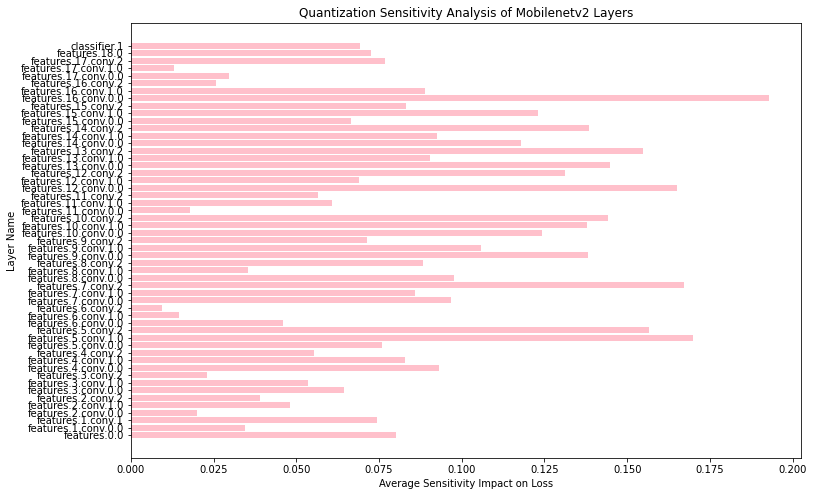

In [11]:
# Define a small epsilon for perturbation
import matplotlib.pyplot as plt

epsilon = 1e-5
model.train()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Function to measure the impact of perturbations
def measure_perturbation_impact(model, dataloader, epsilon):
    sensitivity = {}
    
    inputs, labels = next(iter(dataloader))
    inputs, labels = inputs.to(device), labels.to(device)
    
    # Calculate original loss
    outputs = model(inputs)
    original_loss = criterion(outputs, labels).item()

    for name, layer in model.named_modules():
        if isinstance(layer, (nn.Conv2d, nn.Linear)):
            layer_name = name
            sensitivity[layer_name] = []
            
            for param in layer.parameters():
                # Perturb the weights
                original_weight = param.data.clone()
                param.data += epsilon * torch.sign(torch.randn_like(param.data))
                
                # Measure the loss after perturbation
                outputs = model(inputs)
                perturbed_loss = criterion(outputs, labels).item()
                
                # Calculate the impact as the absolute difference in loss
                sensitivity_impact = abs(perturbed_loss - original_loss)
                sensitivity[layer_name].append(sensitivity_impact)
                
                # Restore the original weights
                param.data = original_weight

    return sensitivity

# Perform the sensitivity analysis
sensitivity = measure_perturbation_impact(model, val_dataloader, epsilon)

# Visualize the results
layer_names = []
sensitivity_values = []

for layer_name, impacts in sensitivity.items():
    avg_sensitivity = sum(impacts) / len(impacts)
    layer_names.append(layer_name)
    sensitivity_values.append(avg_sensitivity)

plt.figure(figsize=(12, 8))
plt.barh(layer_names, sensitivity_values, color='pink')
plt.xlabel('Average Sensitivity Impact on Loss')
plt.ylabel('Layer Name')
plt.title('Quantization Sensitivity Analysis of Mobilenetv2 Layers')
plt.show()

In [ ]:
# Enable gradient computation for all parameters
for param in model.parameters():
    param.requires_grad = True

In [ ]:
def measure_normalized_gradient_sensitivity(model, dataloader, criterion):
    sensitivity_per_layer = {}
    parameter_size_per_layer = {}

    # Get a batch of inputs and labels from the dataloader
    inputs, labels = next(iter(dataloader))
    inputs, labels = inputs.to(device), labels.to(device)

    # Set model to training mode (if any dropout or BN layers)
    model.train()

    # Zero out gradients
    model.zero_grad()

    # Forward pass to calculate outputs and original loss
    outputs = model(inputs)
    original_loss = criterion(outputs, labels)
    
    # Backward pass to calculate gradients
    original_loss.backward()

    # Iterate through layers and compute gradient-based sensitivity
    for name, layer in model.named_modules():
        if isinstance(layer, (torch.nn.Conv2d, torch.nn.Linear)):  # Only focus on convolutional and linear layers
            layer_name = name
            total_sensitivity = 0
            total_params = 0

            # Loop through each parameter in the layer (weights and biases)
            for param in layer.parameters():
                if param.grad is not None:
                    # Calculate sensitivity as the sum of absolute gradients
                    sensitivity = param.grad.abs().sum().item()
                    total_sensitivity += sensitivity
                    total_params += param.numel()

            # Normalize the sensitivity by the number of parameters
            if total_params > 0:
                sensitivity_per_layer[layer_name] = total_sensitivity / total_params
            else:
                sensitivity_per_layer[layer_name] = 0

            # Store parameter size for future use
            parameter_size_per_layer[layer_name] = total_params

    return sensitivity_per_layer, parameter_size_per_layer

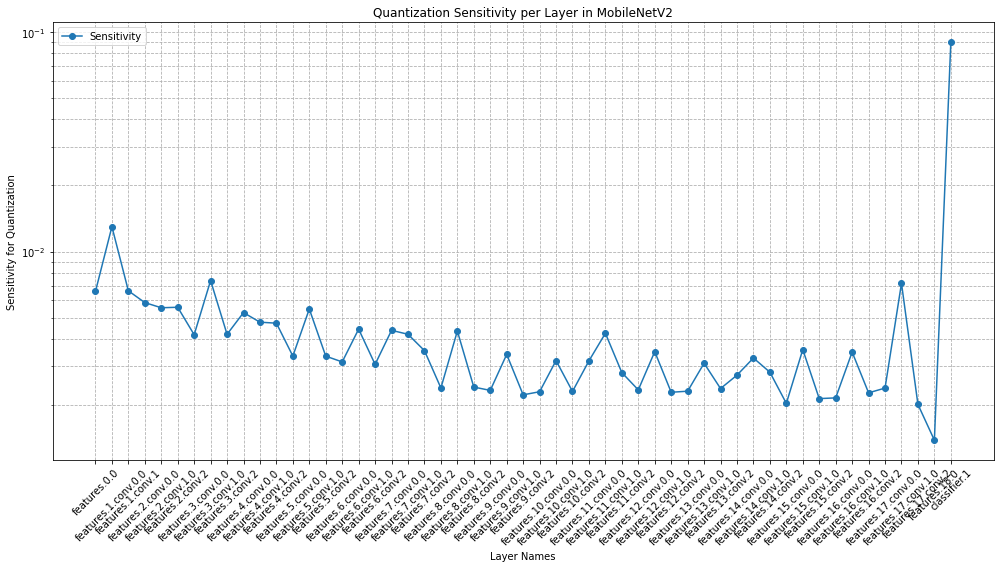

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming sensitivity_per_layer and parameter_size_per_layer are dictionaries with the same keys
layer_names = list(sensitivity_per_layer.keys())  # Ensure layer names are in a consistent order
sensitivity_values = [sensitivity_per_layer[name] for name in layer_names]
parameter_sizes = [parameter_size_per_layer[name] for name in layer_names]

# Normalize data if necessary (if scales are too different to be meaningfully plotted on the same graph)
sensitivity_norm = np.log10(sensitivity_values)  # Converting to a log scale if values vary widely
parameter_sizes_norm = np.log10(parameter_sizes)  # Same as above

plt.figure(figsize=(14, 8))
plt.plot(layer_names, sensitivity_values, marker='o', label='Sensitivity')
# plt.plot(layer_names, parameter_sizes, marker='x', label='Parameter Size')

plt.xlabel('Layer Names')
plt.ylabel('Sensitivity for Quantization')
plt.title('Quantization Sensitivity per Layer in MobileNetV2')
plt.xticks(rotation=45)  # Rotate layer names for better readability
plt.yscale('log')  # Set y-axis to log scale
plt.legend()
plt.grid(True, which="both", ls="--")  # Adding gridlines for better visualization
plt.tight_layout()  # Adjust layout to make room for label rotation
plt.show()

In [13]:
import torch
import torch.nn.functional as F

def measure_saliency_importance(model, dataloader):
    model.eval()
    saliency_per_layer = {}
    parameter_size_per_layer = {}

    # Get a batch of inputs from the dataloader
    inputs, labels = next(iter(dataloader))
    inputs, labels = inputs.to(device), labels.to(device)

    # Enable gradient calculation for inputs
    inputs.requires_grad_()

    # Forward pass
    outputs = model(inputs)
    # Use the max logit (confidence of the most confident class) for saliency
    max_logit, _ = torch.max(outputs, dim=1)
    max_logit = max_logit.mean()  # Aggregate over the batch

    # Backward pass to calculate gradients w.r.t the input
    max_logit.backward()

    # Iterate through layers and compute saliency-based importance
    for name, layer in model.named_modules():
        if isinstance(layer, (torch.nn.Conv2d, torch.nn.Linear)):  # Focus on convolutional and linear layers
            layer_name = name
            saliency = 0
            total_params = 0

            # Sum absolute gradients for each layer's parameters
            for param in layer.parameters():
                if param.grad is not None:
                    saliency += param.grad.abs().sum().item()
                    total_params += param.numel()

            # Store the saliency importance
            saliency_per_layer[layer_name] = saliency
            parameter_size_per_layer[layer_name] = total_params

    return saliency_per_layer, parameter_size_per_layer

# Example usage:
saliency_per_layer, parameter_size_per_layer = measure_saliency_importance(model, val_dataloader)

# Combine saliency importance with previous gradient sensitivity
def combine_sensitivity_saliency(sensitivity_per_layer, saliency_per_layer):
    combined_importance = {}
    for layer in sensitivity_per_layer.keys():
        # Combine gradient sensitivity and saliency (e.g., using a simple weighted sum)
        combined_importance[layer] = sensitivity_per_layer[layer] + saliency_per_layer.get(layer, 0)
    return combined_importance

# Combine the sensitivity and saliency values for informed quantization
combined_importance_per_layer = combine_sensitivity_saliency(sensitivity_per_layer, saliency_per_layer)

# Output the combined importance
for layer, importance in combined_importance_per_layer.items():
    print(f"Layer: {layer}, Combined Importance: {importance}")

Layer: features.0.0, Combined Importance: 43.21858313900453
Layer: features.1.conv.0.0, Combined Importance: 55.34009973042541
Layer: features.1.conv.1, Combined Importance: 61.69250789657235
Layer: features.2.conv.0.0, Combined Importance: 33.913015961647034
Layer: features.2.conv.1.0, Combined Importance: 58.62659766607814
Layer: features.2.conv.2, Combined Importance: 87.94513091941674
Layer: features.3.conv.0.0, Combined Importance: 53.48125705316111
Layer: features.3.conv.1.0, Combined Importance: 88.47084204208704
Layer: features.3.conv.2, Combined Importance: 131.97501032109614
Layer: features.4.conv.0.0, Combined Importance: 69.24952216170452
Layer: features.4.conv.1.0, Combined Importance: 59.98999272562839
Layer: features.4.conv.2, Combined Importance: 168.94818703085184
Layer: features.5.conv.0.0, Combined Importance: 69.56382977714141
Layer: features.5.conv.1.0, Combined Importance: 89.08540254058661
Layer: features.5.conv.2, Combined Importance: 149.84034739714116
Layer: f

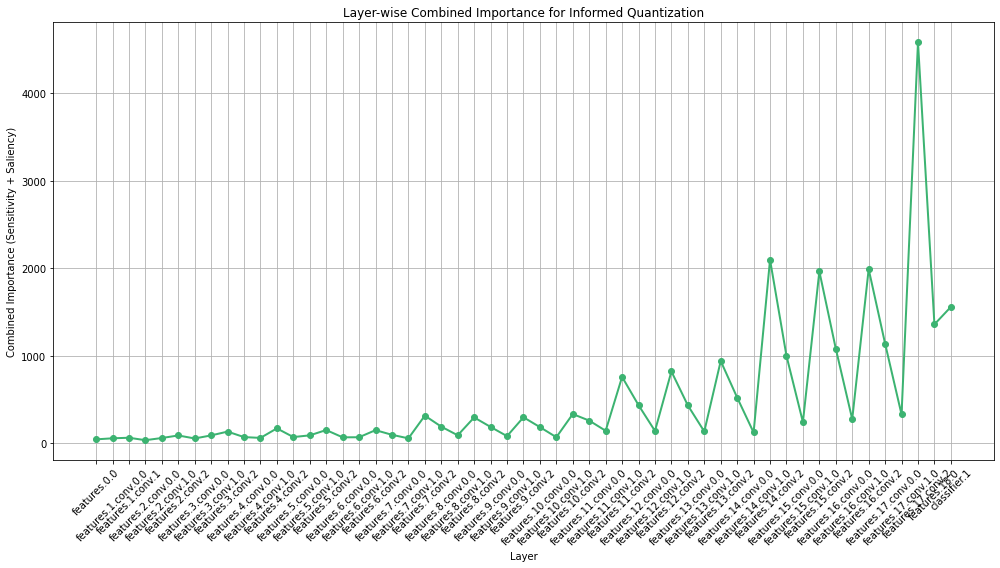

In [14]:
import matplotlib.pyplot as plt

# Assuming combined_importance_per_layer contains the combined importance values for each layer
# Example data structure: {'layer1': importance_value1, 'layer2': importance_value2, ...}

# Extract layer names and combined importance values
layer_names = list(combined_importance_per_layer.keys())
combined_importance_values = list(combined_importance_per_layer.values())

# Plot the combined importance values as a line plot
plt.figure(figsize=(14, 8))
plt.plot(layer_names, combined_importance_values, marker='o', color='mediumseagreen', linestyle='-', linewidth=2)
plt.xlabel('Layer')
plt.ylabel('Combined Importance (Sensitivity + Saliency)')
plt.title('Layer-wise Combined Importance for Informed Quantization')
plt.xticks(rotation=45)  # Rotate layer names for better readability
plt.grid(True)  # Add gridlines for better visualization
plt.tight_layout()
plt.show()

## 7. Quantization-aware training (INT8)
Fine-tune the fake-quantized model for 2 epochs, then export and build the INT8 engine.

In [ ]:
# Finetune the QAT model for 2 epochs
num_epochs=2

for epoch in range(num_epochs):
    print('Epoch: [%5d / %5d] LR: %f' % (epoch + 1, num_epochs, lr))

    train(q_model, train_dataloader, criterion, optimizer, epoch)
    test_loss,test_acc = evaluate(q_model, val_dataloader, criterion, epoch)

    print("Test Acc: {:.2f}%".format(100 * test_acc))
    
save_checkpoint({'epoch': epoch + 1,
                 'model_state_dict': q_model.state_dict(),
                 'acc': test_acc,
                 'opt_state_dict': optimizer.state_dict()
                 },
                ckpt_path="/kaggle/working/mobilenetv2_qat_ckpt")
#torch.save(q_model.state_dict(), "/kaggle/working/mobilenetv2_qat.pth")

In [15]:
# Set static member of TensorQuantizer to use Pytorch’s own fake quantization functions
quant_nn.TensorQuantizer.use_fb_fake_quant = True

# Exporting to Onnx
dummy_input = torch.randn(32, 3, 224, 224, device='cuda')
input_names = [ "actual_input_1" ]
output_names = [ "output1" ]
torch.onnx.export(
    q_model,
    dummy_input,
    "/kaggle/working/mobilenetv2_qat.onnx",
    verbose=False,
    opset_version=13,
    do_constant_folding = False)

# Converting ONNX model to TRT
!/usr/src/tensorrt/bin/trtexec --onnx=/kaggle/working/mobilenetv2_qat.onnx --int8 --useSpinWait --saveEngine=/kaggle/working/mobilenetv2_qat.trt

&&&& RUNNING TensorRT.trtexec [TensorRT v8403] # /usr/src/tensorrt/bin/trtexec --onnx=/kaggle/working/mobilenetv2_qat.onnx --int8 --useSpinWait --saveEngine=/kaggle/working/mobilenetv2_qat.trt
[09/26/2024-23:58:53] [I] === Model Options ===
[09/26/2024-23:58:53] [I] Format: ONNX
[09/26/2024-23:58:53] [I] Model: /kaggle/working/mobilenetv2_qat.onnx
[09/26/2024-23:58:53] [I] Output:
[09/26/2024-23:58:53] [I] === Build Options ===
[09/26/2024-23:58:53] [I] Max batch: explicit batch
[09/26/2024-23:58:53] [I] Memory Pools: workspace: default, dlaSRAM: default, dlaLocalDRAM: default, dlaGlobalDRAM: default
[09/26/2024-23:58:53] [I] minTiming: 1
[09/26/2024-23:58:53] [I] avgTiming: 8
[09/26/2024-23:58:53] [I] Precision: FP32+INT8
[09/26/2024-23:58:53] [I] LayerPrecisions: 
[09/26/2024-23:58:53] [I] Calibration: Dynamic
[09/26/2024-23:58:53] [I] Refit: Disabled
[09/26/2024-23:58:53] [I] Sparsity: Disabled
[09/26/2024-23:58:53] [I] Safe mode: Disabled
[09/26/2024-23:58:53] [I] DirectIO mode: Di

## 8. Results: accuracy and engine size
> **Note on this archived run:** the last size and accuracy lines below were read from a file named
> `resnet50_base_qat.trt` rather than the `mobilenetv2_qat.trt` engine built in section 7, so they are
> not used in the README. The FP16 engine accuracy (88.65%) is also inconsistent with the FP32/INT8
> engines and is excluded. FP32, FP16 latency/size and all INT8 PTQ numbers are used as recorded.

In [ ]:
# Import needed libraries and define the evaluate function

import pycuda.driver as cuda
import pycuda.autoinit
import time 
import tensorrt as trt

def evaluate_trt(engine_path, dataloader, batch_size):
    
    def predict(batch): # result gets copied into output
        # transfer input data to device
        cuda.memcpy_htod_async(d_input, batch, stream)
        # execute model
        context.execute_async_v2(bindings, stream.handle, None)
        # transfer predictions back
        cuda.memcpy_dtoh_async(output, d_output, stream)
        # syncronize threads
        stream.synchronize()
        return output
    
    with open(engine_path, 'rb') as f, trt.Runtime(trt.Logger(trt.Logger.WARNING)) as runtime, runtime.deserialize_cuda_engine(f.read()) as engine, engine.create_execution_context() as context:
        total = 0
        correct = 0
        for images, labels in val_dataloader:
            input_batch = images.numpy()
            labels = labels.numpy()
            output = np.empty([batch_size, 10], dtype = np.float32) 

            # Now allocate input and output memory, give TRT pointers (bindings) to it:
            d_input = cuda.mem_alloc(1 * input_batch.nbytes)
            d_output = cuda.mem_alloc(1 * output.nbytes)
            bindings = [int(d_input), int(d_output)]

            stream = cuda.Stream()
            preds = predict(input_batch)
            pred_labels = []
            for pred in preds:
                pred_label = (-pred).argsort()[0]
                pred_labels.append(pred_label)

            total += len(labels)
            correct += (pred_labels == labels).sum()
    
    return correct/total

In [16]:
# Calculate the size of the file
file_size = os.path.getsize('/kaggle/working/mobilenetv2_base.trt') / (1024 * 1024)  # Convert from bytes to megabytes
print(f'Model size: {file_size:.2f} MB')
file_size = os.path.getsize('/kaggle/working/mobilenetv2_half.trt') / (1024 * 1024)  # Convert from bytes to megabytes
print(f'Model size: {file_size:.2f} MB')
file_size = os.path.getsize('/kaggle/working/mobilenetv2_ptq.trt') / (1024 * 1024)  # Convert from bytes to megabytes
print(f'Model size: {file_size:.2f} MB')
file_size = os.path.getsize('/kaggle/working/resnet50_base_qat.trt') / (1024 * 1024)  # Convert from bytes to megabytes
print(f'Model size: {file_size:.2f} MB')

Model size: 8.73 MB
Model size: 4.82 MB
Model size: 2.88 MB
Model size: 2.88 MB


In [17]:
# Evaluate and benchmark the performance of the baseline TRT model (TRT FP32 Model)
batch_size = 32
test_acc = evaluate_trt("/kaggle/working/mobilenetv2_base.trt", val_dataloader, batch_size)
print("Mobilenetv2 TRT Baseline accuracy: {:.2f}%".format(100 * test_acc))
############################################################################################
test_acc = evaluate_trt("/kaggle/working/mobilenetv2_half.trt", val_dataloader, batch_size)
print("Mobilenetv2 TRT FP16 accuracy: {:.2f}%".format(100 * test_acc))
############################################################################################
test_acc = evaluate_trt("/kaggle/working/mobilenetv2_ptq.trt", val_dataloader, batch_size)
print("Mobilenetv2 TRT PTQ accuracy: {:.2f}%".format(100 * test_acc))
###############################################################################################
test_acc = evaluate_trt("/kaggle/working/resnet50_base_qat.trt", val_dataloader, batch_size)
print("Mobilenetv2 TRT QAT accuracy: {:.2f}%".format(100 * test_acc))

[09/27/2024-00:02:47] [TRT] [W] TensorRT was linked against cuDNN 8.4.1 but loaded cuDNN 8.4.0
[09/27/2024-00:02:47] [TRT] [W] TensorRT was linked against cuDNN 8.4.1 but loaded cuDNN 8.4.0
Mobilenetv2 TRT Baseline accuracy: 98.21%
Mobilenetv2 TRT FP16 accuracy: 88.65%
[09/27/2024-00:03:07] [TRT] [W] TensorRT was linked against cuDNN 8.4.1 but loaded cuDNN 8.4.0
[09/27/2024-00:03:07] [TRT] [W] TensorRT was linked against cuDNN 8.4.1 but loaded cuDNN 8.4.0
Mobilenetv2 TRT PTQ accuracy: 97.46%
[09/27/2024-00:03:16] [TRT] [W] TensorRT was linked against cuDNN 8.4.1 but loaded cuDNN 8.4.0
[09/27/2024-00:03:16] [TRT] [W] TensorRT was linked against cuDNN 8.4.1 but loaded cuDNN 8.4.0
Mobilenetv2 TRT QAT accuracy: 97.52%
